In [214]:
import obspy
import geopandas as gpd
import math
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
import re
from obspy.clients.fdsn.client import Client
import json
from shapely.geometry import LineString
import scipy
import xarray as xr
from matplotlib.colors import LightSource
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
import matplotlib
from matplotlib import colors
from pyproj import Proj
from geopy.distance import geodesic
import pickle
import matplotlib.animation as animation
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 18}) 
from math import radians, cos, sin, atan2, sqrt, degrees
import imageio
from itertools import product
import dask
from dask.diagnostics import ProgressBar
import glob
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)
from pyproj import CRS, Transformer
import re
import obspyh5

In [215]:
grid_df = pd.read_csv('BGRID_station_locations.txt',sep=' ')#,names=['station','network','lat','lon','elev','elev1'])
grid_df

,station,network,longitude,latitude,elevation(m)
0,B00001,CZ,-127.92639,40.26025,0.0
1,B00002,CZ,-127.69200,40.27001,0.0
2,B00003,CZ,-127.45751,40.27931,0.0
3,B00004,CZ,-127.22290,40.28812,0.0
4,B00005,CZ,-126.98820,40.29646,0.0
...,...,...,...,...,...
1561,B01562,CZ,-122.15053,49.90397,0.0
1562,B01563,CZ,-121.87206,49.90160,0.0
1563,B01564,CZ,-121.59364,49.89856,0.0
1564,B01565,CZ,-121.31527,49.89484,0.0


In [216]:
# Read in cable locations
north = pd.read_csv('RSNcableroute_north_nostubs_withdepths.xy',delim_whitespace=True, header=None, names=['lat','lon','depth'],comment='>')
south = pd.read_csv('RSNcableroute_south_nostubs_withdepths.xy',delim_whitespace=True, header=None, names=['lat','lon','depth'],comment='>')

In [217]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import LineString


def grid_points_nearest_cable(
    grid_df,
    cable_df,
    grid_lat="latitude",
    grid_lon="longitude",
    cable_lat="lat",
    cable_lon="lon",
    spacing_m=5000,
    max_distance_m=10000,
):
    """Return grid points nearest regularly spaced stations along a cable route.

    Inputs must contain latitude/longitude columns in EPSG:4326.
    spacing_m is the approximate spacing along the cable route, in meters.
    If max_distance_m is set, stations without a grid point within that
    perpendicular distance are omitted.
    """
    if grid_df.empty or cable_df.empty:
        raise ValueError("grid_df and cable_df must not be empty")
    if spacing_m <= 0:
        raise ValueError("spacing_m must be greater than zero")

    # Use a local UTM CRS so distances and route positions are in meters.
    mean_lon = cable_df[cable_lon].mean()
    mean_lat = cable_df[cable_lat].mean()
    utm_zone = int((mean_lon + 180) // 6) + 1
    epsg = 32600 + utm_zone if mean_lat >= 0 else 32700 + utm_zone
    metric_crs = f"EPSG:{epsg}"

    grid = gpd.GeoDataFrame(
        grid_df.copy(),
        geometry=gpd.points_from_xy(grid_df[grid_lon], grid_df[grid_lat]),
        crs="EPSG:4326",
    ).to_crs(metric_crs)

    cable = LineString(zip(cable_df[cable_lon], cable_df[cable_lat]))
    cable = gpd.GeoSeries([cable], crs="EPSG:4326").to_crs(metric_crs).iloc[0]

    # Route positions at approximately 0, spacing_m, 2*spacing_m, ...
    station_distances = np.arange(0, cable.length + 1e-9, spacing_m)
    if station_distances[-1] < cable.length:
        station_distances = np.append(station_distances, cable.length)
    stations = [cable.interpolate(distance) for distance in station_distances]

    # Find the nearest grid point to each route station.
    candidates = []
    available = grid.copy()
    for station_number, (route_distance_m, station) in enumerate(
        zip(station_distances, stations)
    ):
        if available.empty:
            break

        distances = available.geometry.distance(station)
        grid_index = distances.idxmin()
        distance_to_route_m = available.geometry.loc[grid_index].distance(cable)

        if max_distance_m is None or distance_to_route_m <= max_distance_m:
            row = available.loc[grid_index].copy()
            row["station_number"] = station_number
            row["route_distance_m"] = route_distance_m
            row["distance_to_cable_m"] = distance_to_route_m
            candidates.append(row)

        # Prevent the same grid point from being selected at adjacent stations.
        available = available.drop(index=grid_index)

    selected = gpd.GeoDataFrame(candidates, crs=metric_crs)
    if selected.empty:
        return selected.to_crs("EPSG:4326")

    selected = selected.to_crs("EPSG:4326")
    selected["lon"] = selected.geometry.x
    selected["lat"] = selected.geometry.y
    return selected.reset_index(drop=True)

In [218]:
north_nearby_grid = grid_points_nearest_cable(
    grid_df, north
)
south_nearby_grid = grid_points_nearest_cable(
    grid_df, south
)

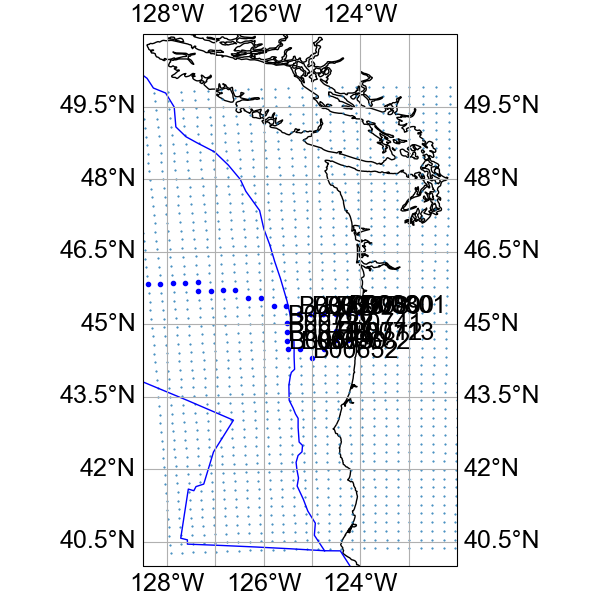

In [219]:
%matplotlib widget

fig = plt.figure(figsize=[6,6],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines()

ax.plot(grid_df.longitude,grid_df.latitude,'.',markersize=1)
# ax.plot(north.lon,north.lat,'k.')
# ax.plot(south.lon,south.lat,'k.')
ax.plot(north_nearby_grid.lon,north_nearby_grid.lat,'b.')
ax.plot(south_nearby_grid.lon,south_nearby_grid.lat,'b.')

# for i in range(len(north_nearby_grid)):
#     ax.text(north_nearby_grid.iloc[i].longitude,north_nearby_grid.iloc[i].latitude,north_nearby_grid.iloc[i].station)

for i in range(len(south_nearby_grid)):
    ax.text(south_nearby_grid.iloc[i].longitude,south_nearby_grid.iloc[i].latitude,south_nearby_grid.iloc[i].station)

# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
ax.set_xlim(-128.5,-122)
ax.set_ylim(40,51)
gl = ax.gridlines(draw_labels=True) 

In [251]:
nearby_grid = pd.concat([south_nearby_grid,north_nearby_grid])

In [252]:
bgrid_added_stations = np.unique(nearby_grid.station.to_list())

In [253]:
len(bgrid_added_stations)

29

## Look at some of the miniseeds

In [223]:
bgrid_path = '/Volumes/Extreme Pro/cascadia_2025_synthetics/audrey_broadband_bgrid/'
scenario = 'buried-random-str10-shallow'

bgrid_st = obspyh5.readh5(bgrid_path+'BGRID_broadband_' + scenario + '.h5')
bgrid_st = bgrid_st.sort(['station'])

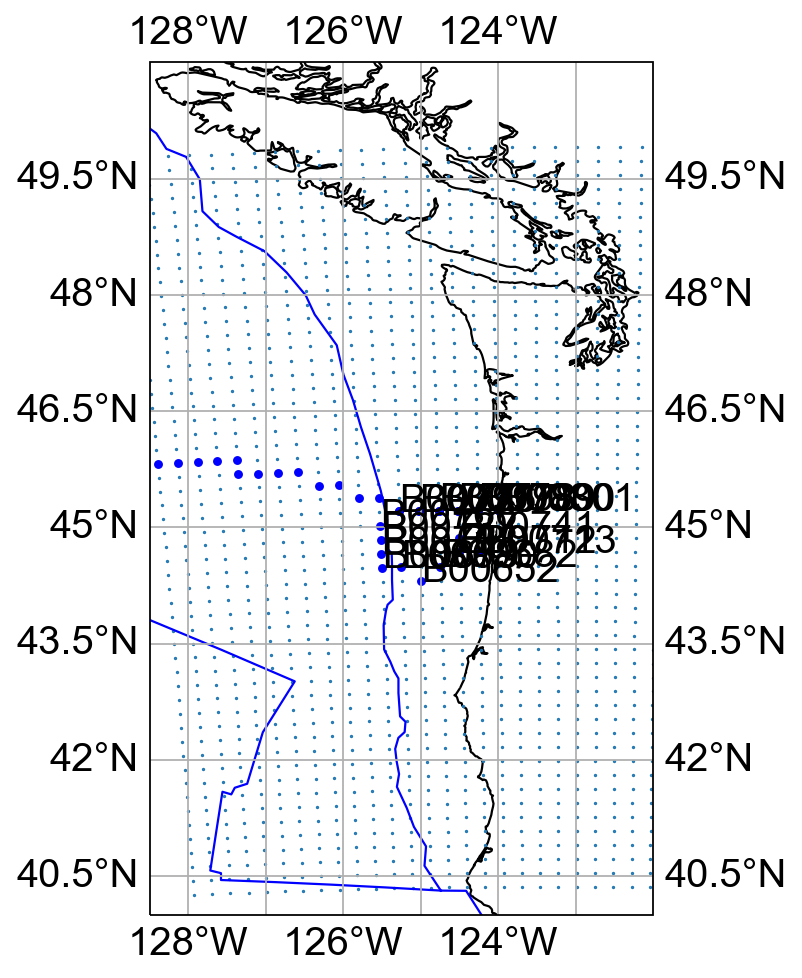

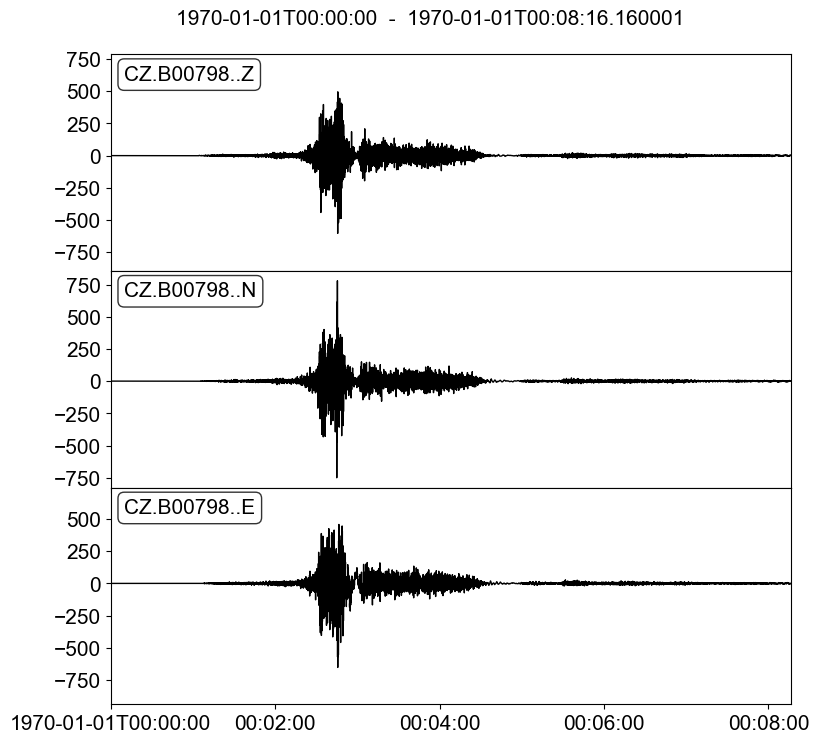

In [224]:
%matplotlib inline
tr = bgrid_st.select(station = 'B00798')
tr.plot();

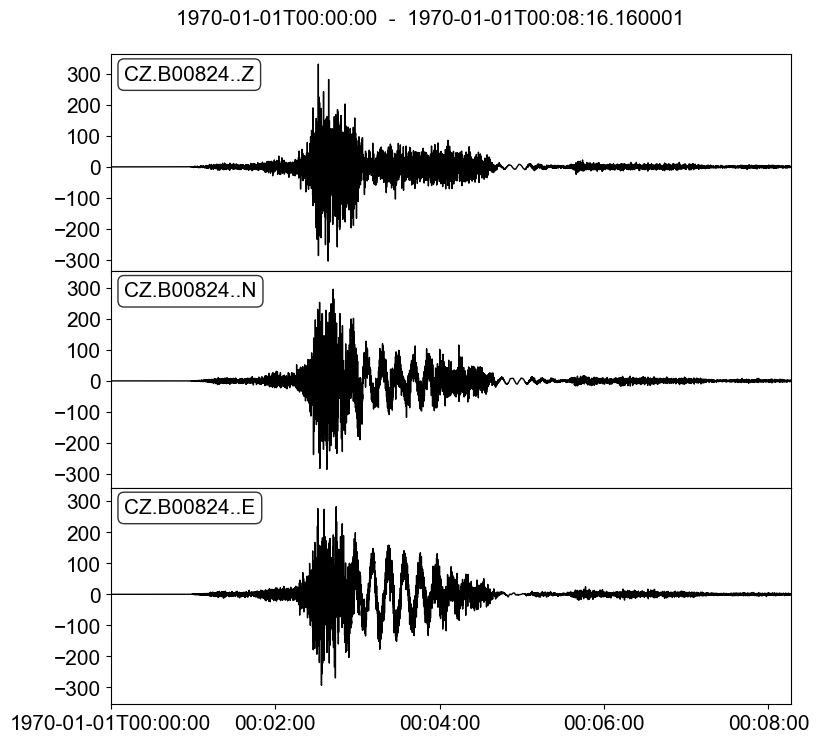

In [225]:
%matplotlib inline
tr = bgrid_st.select(station = 'B00824')
tr.plot();

## Add these BGRID sites to the cascadia_mseeds folder, both full sample rate and downsample rate

In [236]:
write_path = '/Users/zoekrauss/shakealert_8Hz/downsampled_mseeds/'

# BGRID
bgrid_path = '/Volumes/Extreme Pro/cascadia_2025_synthetics/audrey_broadband_bgrid/'

In [237]:
scenarios=(
    'buried-random-str10-shallow',
    'buried-random-str10-deep'
)

In [238]:
# downsample_codes = []
downsample_codes = np.unique(nearby_grid.station.to_list())

In [ ]:
save_folder = 'cascadia_obs_downsampled_mseeds/'


from obspy.signal.filter import lowpass


for scenario in scenarios:

    print(scenario)
    tr_codes = []
    
    # BGRID - only keep the ones we want to add
    bgrid_st = obspyh5.readh5(bgrid_path+'BGRID_broadband_' + scenario + '.h5')
    bgrid_st = bgrid_st.sort(['station'])
    # print(bgrid_st)
    bgrid_keep_st = obspy.Stream()
    for b in range(len(bgrid_added_stations)):
        sta = bgrid_added_stations[b]
        tr = bgrid_st.select(station = sta)
        bgrid_keep_st += tr
    
    st = bgrid_keep_st

    # Change channel name from one character to three (copying Mika's format) because ShakeAlert requires it
    for tr in st:
        
        if tr.stats.channel == 'N':
            tr.stats.channel = 'ENN'
        elif tr.stats.channel == 'E':
            tr.stats.channel = 'ENE'
        elif tr.stats.channel == 'Z':
            tr.stats.channel = 'ENZ'
    
        sta_name = tr.stats.station
        if len(sta_name) > 5:
            new_sta_name = sta_name[1:]
            tr.stats.station = new_sta_name
    
        # New filename based on net, sta, loc, chan
        mseed_name = tr.stats.network + '.' + tr.stats.station + '.' + tr.stats.location + '.' + tr.stats.channel + '.mseed'

        # Add 60 s padding to the start of the waveform
        pad_seconds = 60
        pad_samples = int(pad_seconds * tr.stats.sampling_rate)
        pad_data = np.zeros(pad_samples, dtype = tr.data.dtype)
        tr.data = np.concatenate([pad_data, tr.data])
        # Update metadata
        tr.stats.npts = len(tr.data)
    
        # Multiply data by 10**5 to be able to convert to integers without losing resolution
        tr.data = tr.data * 10**5
    
        # Add some noise to avoid divide by zero STA/LTA issue (same code as Mika)
        tr.data = tr.data + np.random.normal(0, 100, len(tr))

        # Downsample if desired
        if sta_name in downsample_codes:
            # print(sta_name)

            t1 = tr.stats.starttime
            t2 = tr.stats.endtime
            tr.trim(t1-5,t2+5,fill_value=np.int32(np.mean(tr.data)),pad=True) # pad ends so we can cut off edge effects
            tr.resample(8.0,no_filter=False)
            tr.trim(t1,t2)

        else:
            print(sta_name)
            # 10 Hz acausal/zerophase low pass filter (above 10 Hz not trustworthy)
            tr.data = lowpass(tr.data, freq = 10, df = tr.stats.sampling_rate, zerophase = True)        
        
        # Convert to int 
        tr.data = tr.data.astype(int)
    
        # Make writing folder and write trace
        if os.path.isdir(write_path + save_folder + scenario):
            pass
        else:
            os.makedirs(write_path + save_folder + scenario)
    
        # Assuming 'trace' is your ObsPy Trace object with int64 data
        if tr.data.dtype == np.int64:
            tr.data = tr.data.astype(np.int32)
    
        # try:
        tr.write(write_path + save_folder + scenario + '/' + mseed_name, format = 'MSEED',encoding = "INT32")
        # print(write_path + save_folder + scenario + '/' + mseed_name)
        tr_codes.append(tr.stats.network + '.' + tr.stats.station + '.' + tr.stats.channel)
        # except:
        #     print(tr)

    # print('Traces saved (should be comb/uni length + 2 stations * 3 channels each for double WOSB and WSLR):')
    # print(len(tr_codes))
    # print('')

## Now write new .dat files

In [259]:
# Read in old .dat files
starting_file = '/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/cascadia_obs_downsampled_mseeds/cascadia_obs_downsampled_mseeds.dat'

In [260]:
starting_dat = pd.read_csv(starting_file,header=None,sep='\t',names=['network','station','location','channel','latitude','longitude','elevation','samplerate','gain','units'])


In [261]:
nearby_grid = nearby_grid.drop_duplicates(subset='station')

In [262]:
new_station = nearby_grid.station.to_list()
new_network = nearby_grid.network.to_list()
new_longitude = nearby_grid.lon.to_list()
new_latitude = nearby_grid.lat.to_list()

In [263]:
# Below code is largely from Sydney! Thanks Sydney :) 

pd.options.mode.chained_assignment = None

remake_data = list(zip(new_network,new_station,new_latitude,new_longitude))
remake = pd.DataFrame(remake_data, columns=['network','station','latitude','longitude'])
repeat = pd.concat([remake] * 3, ignore_index = True)
repeat = repeat.sort_values(by = ['station']).reset_index(drop = True)
channels = ['ENE', 'ENN', 'ENZ'] * len(remake)
locations = ['--'] * len(repeat)


## Sample rates - be careful here
# samplerates = ['50.0'] * len(repeat)
samplerates = ['8.0'] * len(repeat)



gains = ['100000'] * len(repeat)
units = ['counts/(cm/sec2)'] * len(repeat)
repeat['channel'] = channels
repeat['location'] = locations
repeat['samplerate'] = samplerates
repeat['gain'] = gains
repeat['units'] = units
repeat['elevation'] = ['0.0'] * len(repeat)
repeat = repeat.sort_values(by = ['station', 'channel']).reset_index(drop = True)
station_dat = repeat[['network', 'station', 'location', 'channel', 'latitude', 'longitude', 'elevation', 'samplerate', 'gain', 'units']]


# Rename stations with 6 chars by removing the first one. Need to rename mseed file names too if you made them without fixing this
renamed_dat = station_dat
for j in range(len(renamed_dat)):
    sta = renamed_dat['station'][j]
    if len(sta) > 5:
        # print(sta)
        new_name = sta[1:]
        # print(new_name)
        renamed_dat['station'][j] = new_name



In [264]:
new_dat = pd.concat([starting_dat,renamed_dat])
new_dat

,network,station,location,channel,latitude,longitude,elevation,samplerate,gain,units
0,NP,1023,--,ENE,40.57607,-124.26370,0.0,50.0,100000,counts/(cm/sec2)
1,NP,1023,--,ENN,40.57607,-124.26370,0.0,50.0,100000,counts/(cm/sec2)
2,NP,1023,--,ENZ,40.57607,-124.26370,0.0,50.0,100000,counts/(cm/sec2)
3,NP,1580,--,ENE,40.87772,-124.07738,0.0,50.0,100000,counts/(cm/sec2)
4,NP,1580,--,ENN,40.87772,-124.07738,0.0,50.0,100000,counts/(cm/sec2)
...,...,...,...,...,...,...,...,...,...,...
82,CZ,00903,--,ENN,45.85460,-127.62436,0.0,8.0,100000,counts/(cm/sec2)
83,CZ,00903,--,ENZ,45.85460,-127.62436,0.0,8.0,100000,counts/(cm/sec2)
84,CZ,00904,--,ENE,45.86473,-127.36751,0.0,8.0,100000,counts/(cm/sec2)
85,CZ,00904,--,ENN,45.86473,-127.36751,0.0,8.0,100000,counts/(cm/sec2)


In [265]:
len(starting_dat)

2100

In [266]:
len(renamed_dat)/3

29.0

In [267]:
# Save seismic .dat for replays!
new_dat.to_csv('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/cascadia_obs_downsampled_mseeds/cascadia_das_downsampled_mseeds.dat', sep = '\t', index = False, header = False)


In [ ]:
    'buried-random-str10-shallow',
    'buried-random-str10-deep'

In [268]:
!tar czf /Users/zoekrauss/shakealert_8Hz/downsampled_mseeds/cascadia_obs_downsampled_mseeds/buried-random-str10-shallow.tar.gz  /Users/zoekrauss/shakealert_8Hz/downsampled_mseeds/cascadia_obs_downsampled_mseeds/buried-random-str10-shallow






tar: Removing leading '/' from member names


In [269]:
!tar czf /Users/zoekrauss/shakealert_8Hz/downsampled_mseeds/cascadia_obs_downsampled_mseeds/buried-random-str10-deep.tar.gz  /Users/zoekrauss/shakealert_8Hz/downsampled_mseeds/cascadia_obs_downsampled_mseeds/buried-random-str10-deep



tar: Removing leading '/' from member names


In [145]:
test = obspy.read('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/cascadia_mseeds/buried-random-str10-shallow/CZ.00900..ENZ.mseed')

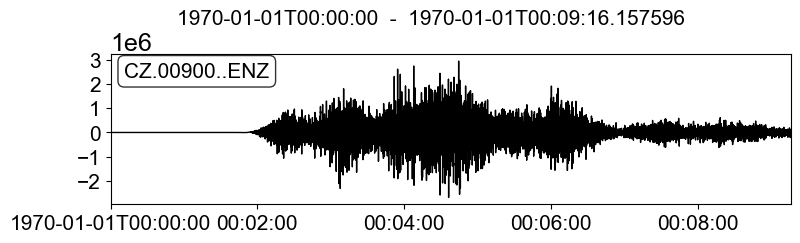

In [146]:
%matplotlib inline
test.plot();

In [147]:
test = obspy.read('/Users/zoekrauss/shakealert_8hz/downsampled_mseeds/cascadia_mseeds/buried-random-str10-shallow/UW.GIGA..ENZ.mseed')

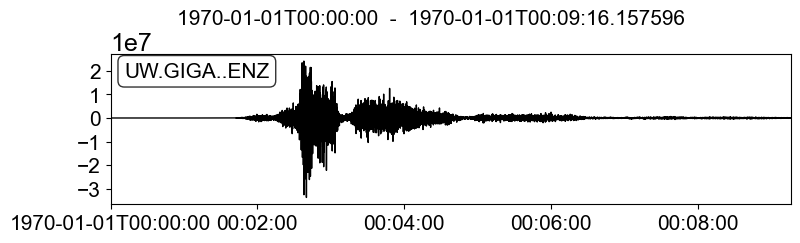

In [148]:
%matplotlib inline
test.plot();